# Team 9 — Multi-Hazard Weather Impact Monitoring

## Workshop 1: Source Profiling and Data Contracts

**Status: executed profiling notebook.** All four source profiles and stored outputs are present. The report/contract changes require a fresh locked-environment execution and mutual review before submission.

**Course:** Data Analysis Programming — 2026-II  
**Institution:** Universidad Distrital Francisco Jose de Caldas  
**Team:** 9  
**Members:** Kevin Rincon and Pablo Garzon  
**Candidate study area:** Oklahoma, United States  
**Status:** Oklahoma/counties accepted; 2010-2025 baseline and rolling 24-hour current window accepted

### Purpose

This notebook profiles preserved, versioned evidence for the four assigned weather sources. The current version implements the NOAA Storm Events and NWS Alerts sections owned by Kevin. Pablo must add GHCN-Daily and NWS Station Observations using the same evidence and profiling standard.

The notebook does not modify raw evidence, perform live API calls, implement production ingestion, or claim that the preliminary Compound Hazard Index has been validated.

## 1. Setup and reproducibility

Source acquisition is handled by scripts under `scripts/workshop_1/`. This notebook reads only preserved local evidence so that rerunning it does not produce different API responses.

The workflow follows the course pattern: load, profile, describe, visualize, identify quality constraints, and document. Raw evidence is never cleaned or overwritten in place.

In [1]:
# Run only in a clean Google Colab environment.
# %pip install -q pandas numpy matplotlib seaborn pyyaml


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Executed at UTC:", datetime.now(timezone.utc).isoformat())

Python: 3.12.16
Platform: Windows-11-10.0.26200-SP0
Pandas: 3.1.1
NumPy: 2.5.4
Executed at UTC: 2026-11-05T18:23:51.235951+00:00


In [3]:
def find_project_root(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "PROJECT_CONTEXT.md").exists():
            return candidate
    raise FileNotFoundError(
        "Repository root not found. Run this notebook from inside the cloned project."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
SAMPLES_ROOT = PROJECT_ROOT / "workshop_1" / "samples"

NOAA_SAMPLE_PATH = SAMPLES_ROOT / "noaa_storm_events" / "details_sample.csv"
NOAA_METADATA_PATH = SAMPLES_ROOT / "noaa_storm_events" / "source_metadata.yaml"
NWS_POLL_1_PATH = SAMPLES_ROOT / "nws_alerts" / "poll_1.geojson"
NWS_POLL_2_PATH = SAMPLES_ROOT / "nws_alerts" / "poll_2.geojson"
NWS_POLL_1_METADATA_PATH = SAMPLES_ROOT / "nws_alerts" / "poll_1_metadata.yaml"
NWS_POLL_2_METADATA_PATH = SAMPLES_ROOT / "nws_alerts" / "poll_2_metadata.yaml"
NWS_RECENT_PAGE_1_PATH = SAMPLES_ROOT / "nws_alerts" / "recent_7d_page_1.geojson"
NWS_RECENT_PAGE_2_PATH = SAMPLES_ROOT / "nws_alerts" / "recent_7d_page_2.geojson"
NWS_RECENT_METADATA_PATH = SAMPLES_ROOT / "nws_alerts" / "recent_7d_metadata.yaml"

print("Project root: repository root")
REGION_COMPARISON_ROOT = SAMPLES_ROOT / "region_comparison"
GHCN_SAMPLE_PATH = REGION_COMPARISON_ROOT / "ghcn_okc_usw00013967_2025.csv"
GHCN_METADATA_PATH = REGION_COMPARISON_ROOT / "source_metadata.yaml"
GHCN_PILOT_PATH = SAMPLES_ROOT / "ghcn_daily_denver_2025-06_to_09.csv"
GHCN_PILOT_METADATA_PATH = SAMPLES_ROOT / "ghcn_daily_denver_2025-06_to_09.metadata.json"
STATION_OBSERVATIONS_PATH = REGION_COMPARISON_ROOT / "nws_kokc_observations_snapshot.geojson"
STATION_OBSERVATIONS_POLL2_PATH = REGION_COMPARISON_ROOT / "nws_kokc_observations_poll_2.geojson"
STATION_OBSERVATIONS_POLL2_METADATA_PATH = REGION_COMPARISON_ROOT / "nws_kokc_observations_poll_2.metadata.json"
STATION_OBSERVATIONS_METADATA_PATH = REGION_COMPARISON_ROOT / "source_metadata.yaml"
CANDIDATE_PAIRS_ROOT = SAMPLES_ROOT / "candidate_pairs"
STATION_HISTORY_PAGE_PATH = CANDIDATE_PAIRS_ROOT / "nws_kokc_observations_page_2.geojson"
CANDIDATE_PAIRS_PATH = CANDIDATE_PAIRS_ROOT / "nws_alerts_kokc_candidate_pairs.csv"
CANDIDATE_PAIRS_METADATA_PATH = CANDIDATE_PAIRS_ROOT / "source_metadata.yaml"

Project root: repository root


### 1.1 Evidence inventory and integrity

Every required artifact must exist and match its registered SHA-256 checksum before profiling begins. A missing or changed file stops the notebook rather than silently producing results from different evidence.

In [4]:
EVIDENCE_PATHS = {
    "NOAA sample": NOAA_SAMPLE_PATH,
    "NOAA metadata": NOAA_METADATA_PATH,
    "GHCN-Daily 2025 sample": GHCN_SAMPLE_PATH,
    "GHCN-Daily 2025 metadata": GHCN_METADATA_PATH,
    "GHCN-Daily exploratory pilot": GHCN_PILOT_PATH,
    "GHCN-Daily exploratory metadata": GHCN_PILOT_METADATA_PATH,
    "NWS station observations poll 1": STATION_OBSERVATIONS_PATH,
    "NWS station observations metadata": STATION_OBSERVATIONS_METADATA_PATH,
    "NWS station observations poll 2": STATION_OBSERVATIONS_POLL2_PATH,
    "NWS station observations poll 2 metadata": STATION_OBSERVATIONS_POLL2_METADATA_PATH,
    "NWS poll 1": NWS_POLL_1_PATH,
    "NWS poll 2": NWS_POLL_2_PATH,
    "NWS poll 1 metadata": NWS_POLL_1_METADATA_PATH,
    "NWS poll 2 metadata": NWS_POLL_2_METADATA_PATH,
    "NWS recent page 1": NWS_RECENT_PAGE_1_PATH,
    "NWS recent page 2": NWS_RECENT_PAGE_2_PATH,
    "NWS recent metadata": NWS_RECENT_METADATA_PATH,
    "KOKC historical pagination page": STATION_HISTORY_PAGE_PATH,
    "Cross-source candidate pairs": CANDIDATE_PAIRS_PATH,
    "Cross-source candidate-pair metadata": CANDIDATE_PAIRS_METADATA_PATH,
}

evidence_inventory = pd.DataFrame([
    {
        "artifact": name,
        "path": str(path.relative_to(PROJECT_ROOT)),
        "exists": path.exists(),
        "bytes": path.stat().st_size if path.exists() else None,
    }
    for name, path in EVIDENCE_PATHS.items()
])
display(evidence_inventory)

missing_files = evidence_inventory.loc[~evidence_inventory["exists"], "artifact"].tolist()
if missing_files:
    raise FileNotFoundError(f"Required evidence is missing: {missing_files}")

,artifact,path,exists,bytes
0,NOAA sample,workshop_1\samples\noaa_storm_events\details_sample.csv,True,276358
1,NOAA metadata,workshop_1\samples\noaa_storm_events\source_metadata.yaml,True,2278
2,GHCN-Daily 2025 sample,workshop_1\samples\region_comparison\ghcn_okc_usw00013967_2025.csv,True,54843
3,GHCN-Daily 2025 metadata,workshop_1\samples\region_comparison\source_metadata.yaml,True,3349
4,GHCN-Daily exploratory pilot,workshop_1\samples\ghcn_daily_denver_2025-06_to_09.csv,True,12887
5,GHCN-Daily exploratory metadata,workshop_1\samples\ghcn_daily_denver_2025-06_to_09.metadata.json,True,1376
6,NWS station observations poll 1,workshop_1\samples\region_comparison\nws_kokc_observations_snapshot.geojson,True,779031
7,NWS station observations metadata,workshop_1\samples\region_comparison\source_metadata.yaml,True,3349
8,NWS station observations poll 2,workshop_1\samples\region_comparison\nws_kokc_observations_poll_2.geojson,True,779027
9,NWS station observations poll 2 metadata,workshop_1\samples\region_comparison\nws_kokc_observations_poll_2.metadata.json,True,1244


In [5]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest().upper()


def load_yaml(path: Path) -> dict:
    with path.open("r", encoding="utf-8") as file:
        return yaml.safe_load(file)


def load_json(path: Path) -> dict:
    with path.open("r", encoding="utf-8") as file:
        return json.load(file)


noaa_metadata = load_yaml(NOAA_METADATA_PATH)
nws_poll_1_metadata = load_yaml(NWS_POLL_1_METADATA_PATH)
nws_poll_2_metadata = load_yaml(NWS_POLL_2_METADATA_PATH)
nws_recent_metadata = load_yaml(NWS_RECENT_METADATA_PATH)
ghcn_metadata = load_yaml(GHCN_METADATA_PATH)
ghcn_pilot_metadata = load_json(GHCN_PILOT_METADATA_PATH)
station_observations_metadata = load_yaml(STATION_OBSERVATIONS_METADATA_PATH)
station_observations_poll2_metadata = load_json(STATION_OBSERVATIONS_POLL2_METADATA_PATH)
candidate_pairs_metadata = load_yaml(CANDIDATE_PAIRS_METADATA_PATH)

integrity_checks = pd.DataFrame([
    {
        "artifact": "GHCN-Daily sample",
        "expected_sha256": ghcn_metadata["ghcn_daily"]["sha256"].upper(),
        "observed_sha256": sha256_file(GHCN_SAMPLE_PATH),
    },
    {
        "artifact": "GHCN-Daily exploratory pilot",
        "expected_sha256": ghcn_pilot_metadata["response"]["sha256"].upper(),
        "observed_sha256": sha256_file(GHCN_PILOT_PATH),
    },
    {
        "artifact": "NWS station observations poll 1",
        "expected_sha256": station_observations_metadata["nws_station_observations"]["sha256"].upper(),
        "observed_sha256": sha256_file(STATION_OBSERVATIONS_PATH),
    },
    {
        "artifact": "NWS station observations poll 2",
        "expected_sha256": station_observations_poll2_metadata["sha256"].upper(),
        "observed_sha256": sha256_file(STATION_OBSERVATIONS_POLL2_PATH),
    },
    {
        "artifact": "NOAA sample",
        "expected_sha256": noaa_metadata["sample"]["sha256"],
        "observed_sha256": sha256_file(NOAA_SAMPLE_PATH),
    },
    {
        "artifact": "NWS poll 1",
        "expected_sha256": nws_poll_1_metadata["evidence"]["sha256"],
        "observed_sha256": sha256_file(NWS_POLL_1_PATH),
    },
    {
        "artifact": "NWS poll 2",
        "expected_sha256": nws_poll_2_metadata["evidence"]["sha256"],
        "observed_sha256": sha256_file(NWS_POLL_2_PATH),
    },
    {
        "artifact": "NWS recent page 1",
        "expected_sha256": nws_recent_metadata["pagination"]["page_1"]["sha256"],
        "observed_sha256": sha256_file(NWS_RECENT_PAGE_1_PATH),
    },
    {
        "artifact": "NWS recent page 2",
        "expected_sha256": nws_recent_metadata["pagination"]["page_2"]["sha256"],
        "observed_sha256": sha256_file(NWS_RECENT_PAGE_2_PATH),
    },
    {
        "artifact": "KOKC historical pagination page",
        "expected_sha256": candidate_pairs_metadata["raw_page"]["sha256"],
        "observed_sha256": sha256_file(STATION_HISTORY_PAGE_PATH),
    },
    {
        "artifact": "Cross-source candidate pairs",
        "expected_sha256": candidate_pairs_metadata["derived_pairs"]["sha256"],
        "observed_sha256": sha256_file(CANDIDATE_PAIRS_PATH),
    },
])
integrity_checks["matches"] = (
    integrity_checks["expected_sha256"] == integrity_checks["observed_sha256"]
)
display(integrity_checks)
assert integrity_checks["matches"].all(), "At least one evidence checksum does not match."

,artifact,expected_sha256,observed_sha256,matches
0,GHCN-Daily sample,D8EE9E0AFBFE25897C17BABE4A88DC0E12D4FECE8B74C26E8D817D5309FFB5AE,D8EE9E0AFBFE25897C17BABE4A88DC0E12D4FECE8B74C26E8D817D5309FFB5AE,True
1,GHCN-Daily exploratory pilot,9E5F1FED70C5B4EF8194A346A8EA03648B64D12BA57FD90D261D4A807ADCE901,9E5F1FED70C5B4EF8194A346A8EA03648B64D12BA57FD90D261D4A807ADCE901,True
2,NWS station observations poll 1,391C49B75E7E05C225FE0EB63BB7BB822004169FFBB0F8FF6DDA006F236B0E68,391C49B75E7E05C225FE0EB63BB7BB822004169FFBB0F8FF6DDA006F236B0E68,True
3,NWS station observations poll 2,7857DD85FB4F35E33FA4A0EEFB0F07E6634E457D96F6A0D4C30560B5CDD07D79,7857DD85FB4F35E33FA4A0EEFB0F07E6634E457D96F6A0D4C30560B5CDD07D79,True
4,NOAA sample,987F5C641B6B85BF89477A823B52757D50D2C5376895FD53056A9AFE9F79403A,987F5C641B6B85BF89477A823B52757D50D2C5376895FD53056A9AFE9F79403A,True
5,NWS poll 1,1D0E2E7AA61FB7F1C43913FB4A7A58BB6FA31922516D6CC4E50166009CCED27D,1D0E2E7AA61FB7F1C43913FB4A7A58BB6FA31922516D6CC4E50166009CCED27D,True
6,NWS poll 2,5932B237B6751B92C46BFB5B6BD6A2F444522F4614B12D6DD1E72FC65C56716C,5932B237B6751B92C46BFB5B6BD6A2F444522F4614B12D6DD1E72FC65C56716C,True
7,NWS recent page 1,70AD394CF9E7399ACCB5CEA7B0A3B8E55526F01C314E68136439EA8442E966C3,70AD394CF9E7399ACCB5CEA7B0A3B8E55526F01C314E68136439EA8442E966C3,True
8,NWS recent page 2,4CB866FDD600EAC1EBDFFEF103B4F8B27E84D15EB8221914167420D158261574,4CB866FDD600EAC1EBDFFEF103B4F8B27E84D15EB8221914167420D158261574,True
9,KOKC historical pagination page,A13720F4E561AC3B20E56DD15F9D43224A1EF1ABE84D37E58DF5BF5FE38BA5CD,A13720F4E561AC3B20E56DD15F9D43224A1EF1ABE84D37E58DF5BF5FE38BA5CD,True


### 1.2 Reusable profiling helpers

In [6]:
def stable_value(value):
    if isinstance(value, (list, dict)):
        return json.dumps(value, sort_keys=True, default=str)
    return value


def safe_nunique(series: pd.Series) -> int:
    return series.dropna().map(stable_value).nunique()


def dataframe_profile(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for column in df.columns:
        series = df[column]
        rows.append({
            "column": column,
            "dtype": str(series.dtype),
            "non_null": int(series.notna().sum()),
            "null_count": int(series.isna().sum()),
            "null_pct": round(float(series.isna().mean() * 100), 2),
            "distinct": int(safe_nunique(series)),
        })
    return (
        pd.DataFrame(rows)
        .sort_values(["null_pct", "distinct"], ascending=[False, True])
        .reset_index(drop=True)
    )


def load_geojson(path: Path) -> dict:
    with path.open("r", encoding="utf-8") as file:
        payload = json.load(file)
    if payload.get("type") != "FeatureCollection":
        raise ValueError(f"{path.name} is not a GeoJSON FeatureCollection.")
    return payload

## 2. NOAA Storm Events

The evidence is a deterministic 250-record subset of the official 2024 Storm Events details archive. It preserves all 51 source columns and represents 14 selected hazard types for Oklahoma. The untouched compressed archive remains in ignored raw storage.

In [7]:
noaa_raw = pd.read_csv(NOAA_SAMPLE_PATH, dtype="string", keep_default_na=True)
noaa = noaa_raw.copy()

print("Rows:", len(noaa_raw))
print("Columns:", noaa_raw.shape[1])
display(noaa_raw.head())

assert len(noaa_raw) >= 200, "NOAA evidence does not meet the Workshop 1 record threshold."

Rows: 250
Columns: 51


,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,YEAR,MONTH_NAME,EVENT_TYPE,CZ_TYPE,CZ_FIPS,CZ_NAME,WFO,BEGIN_DATE_TIME,CZ_TIMEZONE,END_DATE_TIME,INJURIES_DIRECT,INJURIES_INDIRECT,DEATHS_DIRECT,DEATHS_INDIRECT,DAMAGE_PROPERTY,DAMAGE_CROPS,SOURCE,MAGNITUDE,MAGNITUDE_TYPE,FLOOD_CAUSE,CATEGORY,TOR_F_SCALE,TOR_LENGTH,TOR_WIDTH,TOR_OTHER_WFO,TOR_OTHER_CZ_STATE,TOR_OTHER_CZ_FIPS,TOR_OTHER_CZ_NAME,BEGIN_RANGE,BEGIN_AZIMUTH,BEGIN_LOCATION,END_RANGE,END_AZIMUTH,END_LOCATION,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EPISODE_NARRATIVE,EVENT_NARRATIVE,DATA_SOURCE
0,202401,8,600,202401,9,0,188112,1155350,OKLAHOMA,40,2024,January,Heavy Snow,Z,1,CIMARRON,AMA,08-JAN-24 06:00:00,CST-6,09-JAN-24 00:00:00,0,0,0,0,<NA>,<NA>,CoCoRaHS,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,A strong low pressure system brought severe winds and snow to the combined Panhandles. With sustained winds reaching...,Snowfall was measured between 4 and 7 of snow from the storm system that brought blizzard conditions.,CSV
1,202401,8,1200,202401,8,2000,188112,1155307,OKLAHOMA,40,2024,January,High Wind,Z,2,TEXAS,AMA,08-JAN-24 12:00:00,CST-6,08-JAN-24 20:00:00,0,0,0,0,<NA>,<NA>,Mesonet,39.00,MS,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,A strong low pressure system brought severe winds and snow to the combined Panhandles. With sustained winds reaching...,Sustained winds at three different mesonets were reaching speeds of 40 to 45 mph throughout the afternoon and early ...,CSV
2,202401,8,1255,202401,8,1625,188112,1155308,OKLAHOMA,40,2024,January,High Wind,Z,1,CIMARRON,AMA,08-JAN-24 12:55:00,CST-6,08-JAN-24 16:25:00,0,0,0,0,<NA>,<NA>,Mesonet,51.00,MG,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,A strong low pressure system brought severe winds and snow to the combined Panhandles. With sustained winds reaching...,The mesonet located near Boise City measure gusts of 58 and 59 mph between 1255CST and 1625CST.,CSV
3,202401,8,1310,202401,8,1957,188112,1155306,OKLAHOMA,40,2024,January,High Wind,Z,2,TEXAS,AMA,08-JAN-24 13:10:00,CST-6,08-JAN-24 19:57:00,0,0,0,0,<NA>,<NA>,ASOS,64.00,MG,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,A strong low pressure system brought severe winds and snow to the combined Panhandles. With sustained winds reaching...,Several mesonets located in the county and the Guymon ASOS measured sustained winds of 35 to 45 mph with gusts upwar...,CSV
4,202401,8,1500,202401,8,2359,188112,1155309,OKLAHOMA,40,2024,January,High Wind,Z,1,CIMARRON,AMA,08-JAN-24 15:00:00,CST-6,08-JAN-24 23:59:00,0,0,0,0,<NA>,<NA>,Mesonet,39.00,MS,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,A strong low pressure system brought severe winds and snow to the combined Panhandles. With sustained winds reaching...,Sustained winds in Cimarron County were between 40 and 45 mph between 1500CST and 2359CST on the 8th of January 2024.,CSV


### 2.1 Schema, missingness, and identifiers

In [8]:
noaa_profile = dataframe_profile(noaa_raw)
display(noaa_profile)

noaa_id_summary = pd.DataFrame([{
    "rows": len(noaa_raw),
    "distinct_event_ids": noaa_raw["EVENT_ID"].nunique(dropna=True),
    "missing_event_ids": noaa_raw["EVENT_ID"].isna().sum(),
    "duplicated_event_ids": noaa_raw["EVENT_ID"].duplicated(keep=False).sum(),
    "exact_duplicate_rows": noaa_raw.duplicated().sum(),
}])
display(noaa_id_summary)

,column,dtype,non_null,null_count,null_pct,distinct
0,CATEGORY,string,0,250,100.0,0
1,TOR_F_SCALE,string,0,250,100.0,0
2,TOR_LENGTH,string,0,250,100.0,0
3,TOR_WIDTH,string,0,250,100.0,0
4,TOR_OTHER_WFO,string,0,250,100.0,0
5,TOR_OTHER_CZ_STATE,string,0,250,100.0,0
6,TOR_OTHER_CZ_FIPS,string,0,250,100.0,0
7,TOR_OTHER_CZ_NAME,string,0,250,100.0,0
8,FLOOD_CAUSE,string,37,213,85.2,1
9,MAGNITUDE_TYPE,string,52,198,79.2,3


,rows,distinct_event_ids,missing_event_ids,duplicated_event_ids,exact_duplicate_rows
0,250,250,0,0,0


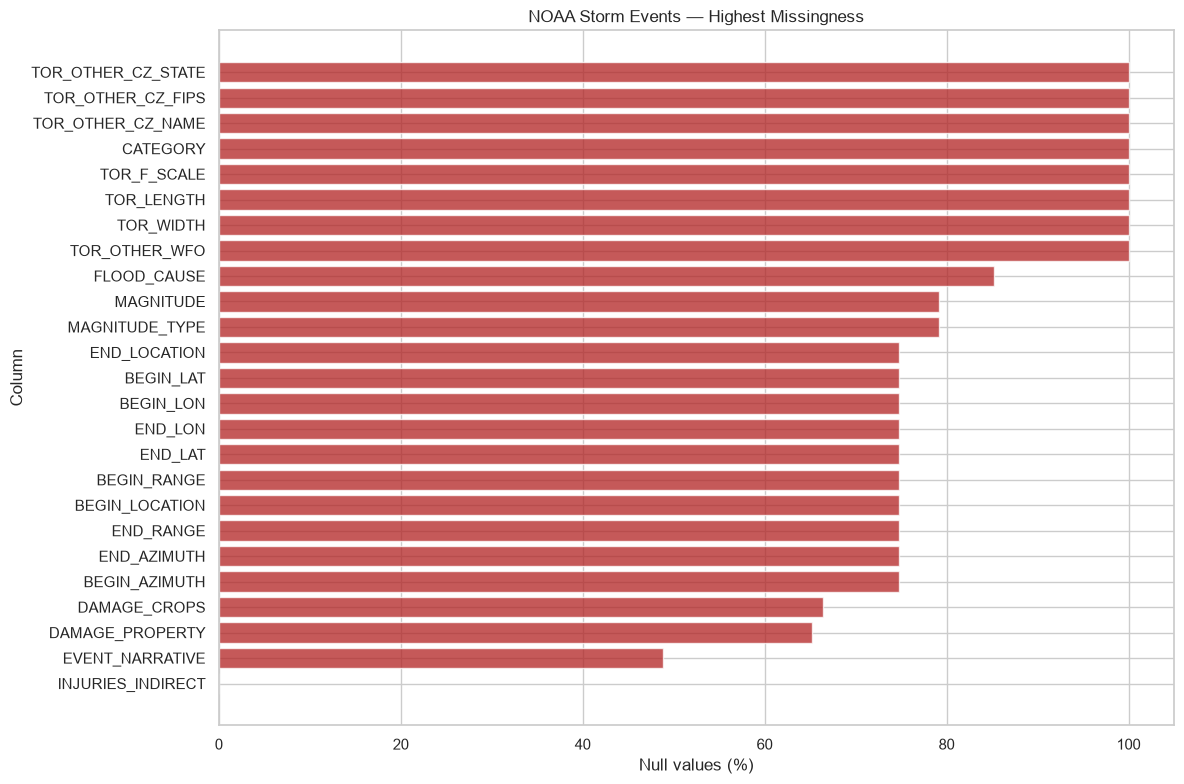

In [9]:
fig, ax = plt.subplots(figsize=(12, 8))
null_plot = noaa_profile.sort_values("null_pct", ascending=True).tail(25)
ax.barh(null_plot["column"], null_plot["null_pct"], color="firebrick", alpha=0.75)
ax.set(title="NOAA Storm Events — Highest Missingness", xlabel="Null values (%)", ylabel="Column")
plt.tight_layout()
plt.show()

### 2.2 Temporal and geographic validation

Storm Events timestamps are parsed as source-local times. `CZ_TIMEZONE` must be interpreted before production UTC conversion; this notebook does not silently label local values as UTC.

In [10]:
noaa["BEGIN_PARSED_LOCAL"] = pd.to_datetime(
    noaa["BEGIN_DATE_TIME"], format="%d-%b-%y %H:%M:%S", errors="coerce"
)
noaa["END_PARSED_LOCAL"] = pd.to_datetime(
    noaa["END_DATE_TIME"], format="%d-%b-%y %H:%M:%S", errors="coerce"
)
noaa["DURATION_HOURS"] = (
    noaa["END_PARSED_LOCAL"] - noaa["BEGIN_PARSED_LOCAL"]
).dt.total_seconds() / 3600

for column in ["BEGIN_LAT", "BEGIN_LON", "END_LAT", "END_LON", "MAGNITUDE"]:
    noaa[column + "_NUM"] = pd.to_numeric(noaa[column], errors="coerce")

temporal_summary = pd.DataFrame([{
    "begin_parse_failures": noaa["BEGIN_PARSED_LOCAL"].isna().sum(),
    "end_parse_failures": noaa["END_PARSED_LOCAL"].isna().sum(),
    "minimum_begin_local": noaa["BEGIN_PARSED_LOCAL"].min(),
    "maximum_end_local": noaa["END_PARSED_LOCAL"].max(),
    "negative_duration_records": (noaa["DURATION_HOURS"] < 0).sum(),
    "timezone_values": noaa["CZ_TIMEZONE"].nunique(dropna=True),
}])
display(temporal_summary)

coordinate_summary = pd.DataFrame([{
    "missing_begin_coordinates": (noaa["BEGIN_LAT_NUM"].isna() | noaa["BEGIN_LON_NUM"].isna()).sum(),
    "invalid_begin_latitude": (~noaa["BEGIN_LAT_NUM"].between(-90, 90) & noaa["BEGIN_LAT_NUM"].notna()).sum(),
    "invalid_begin_longitude": (~noaa["BEGIN_LON_NUM"].between(-180, 180) & noaa["BEGIN_LON_NUM"].notna()).sum(),
}])
display(coordinate_summary)

,begin_parse_failures,end_parse_failures,minimum_begin_local,maximum_end_local,negative_duration_records,timezone_values
0,0,0,2024-01-08 06:00:00,2024-11-09,0,1


,missing_begin_coordinates,invalid_begin_latitude,invalid_begin_longitude
0,187,0,0


### 2.3 Event and geographic distributions

,event_type,count
0,Cold/Wind Chill,49
1,High Wind,25
2,Winter Weather,25
3,Thunderstorm Wind,25
4,Flash Flood,25
5,Heat,25
6,Excessive Heat,25
7,Winter Storm,15
8,Flood,12
9,Heavy Snow,10


,cz_type,count
0,Z,187
1,C,63


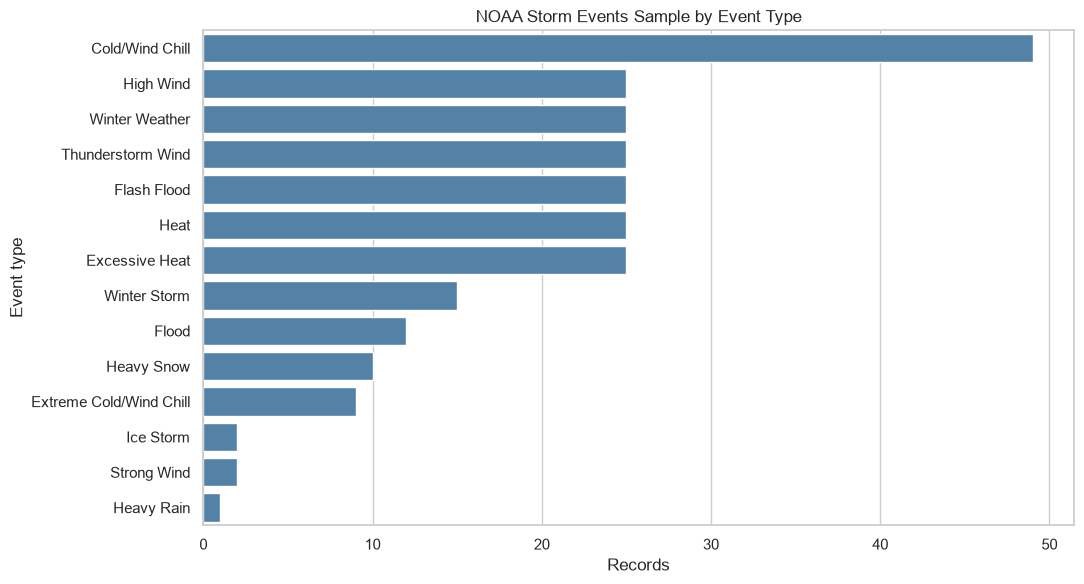

In [11]:
event_counts = noaa["EVENT_TYPE"].value_counts(dropna=False).rename_axis("event_type").reset_index(name="count")
cz_type_counts = noaa["CZ_TYPE"].value_counts(dropna=False).rename_axis("cz_type").reset_index(name="count")
display(event_counts)
display(cz_type_counts)

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=event_counts, x="count", y="event_type", ax=ax, color="steelblue")
ax.set(title="NOAA Storm Events Sample by Event Type", xlabel="Records", ylabel="Event type")
plt.tight_layout()
plt.show()

## 3. NWS Alerts

Two active-state polls were captured more than one hour apart. Both were valid empty FeatureCollections. A separately labeled recent-window response contains 238 alerts for field profiling and does not replace the incremental polls.

In [12]:
nws_poll_1 = load_geojson(NWS_POLL_1_PATH)
nws_poll_2 = load_geojson(NWS_POLL_2_PATH)
nws_recent_page_1 = load_geojson(NWS_RECENT_PAGE_1_PATH)
nws_recent_page_2 = load_geojson(NWS_RECENT_PAGE_2_PATH)

nws_poll_summary = pd.DataFrame([
    {
        "poll": "poll_1",
        "retrieved_at_utc": nws_poll_1_metadata["retrieved_at_utc"],
        "collection_updated": nws_poll_1.get("updated"),
        "feature_count": len(nws_poll_1.get("features", [])),
        "sha256": sha256_file(NWS_POLL_1_PATH),
    },
    {
        "poll": "poll_2",
        "retrieved_at_utc": nws_poll_2_metadata["retrieved_at_utc"],
        "collection_updated": nws_poll_2.get("updated"),
        "feature_count": len(nws_poll_2.get("features", [])),
        "sha256": sha256_file(NWS_POLL_2_PATH),
    },
])
display(nws_poll_summary)

,poll,retrieved_at_utc,collection_updated,feature_count,sha256
0,poll_1,2026-11-04T19:14:33.7862514Z,2026-11-04T19:13:19+00:00,0,1D0E2E7AA61FB7F1C43913FB4A7A58BB6FA31922516D6CC4E50166009CCED27D
1,poll_2,2026-11-04T20:49:29Z,2026-11-04T20:45:06+00:00,0,5932B237B6751B92C46BFB5B6BD6A2F444522F4614B12D6DD1E72FC65C56716C


### 3.1 Recent-window pagination and schema

In [13]:
recent_pages = [nws_recent_page_1, nws_recent_page_2]
pagination_summary = pd.DataFrame([
    {
        "page": index,
        "features": len(page.get("features", [])),
        "next_cursor_present": bool(page.get("pagination", {}).get("next")),
        "updated": page.get("updated"),
    }
    for index, page in enumerate(recent_pages, start=1)
])
display(pagination_summary)

recent_features = [
    feature
    for page in recent_pages
    for feature in page.get("features", [])
]
assert len(recent_features) >= 200, "NWS evidence does not meet the Workshop 1 record threshold."

nws_raw = pd.json_normalize(recent_features, sep=".")
print("Recent alert features:", len(recent_features))
print("Normalized columns:", nws_raw.shape[1])
display(nws_raw.head())

,page,features,next_cursor_present,updated
0,1,238,True,2026-11-03T09:57:13+00:00
1,2,0,False,2026-11-03T09:57:13+00:00


Recent alert features: 238
Normalized columns: 58


,id,type,geometry,properties.@id,properties.@type,properties.id,properties.areaDesc,properties.geocode.SAME,properties.geocode.UGC,properties.affectedZones,properties.references,properties.sent,properties.effective,properties.onset,properties.expires,properties.ends,properties.status,properties.messageType,properties.category,properties.severity,properties.certainty,properties.urgency,properties.event,properties.sender,properties.senderName,properties.headline,properties.description,properties.instruction,properties.response,properties.note,properties.parameters.AWIPSidentifier,properties.parameters.WMOidentifier,properties.parameters.NWSheadline,properties.parameters.BLOCKCHANNEL,properties.parameters.VTEC,properties.parameters.eventEndingTime,properties.parameters.expiredReferences,properties.scope,properties.code,properties.language,properties.web,properties.eventCode.SAME,properties.eventCode.NationalWeatherService,geometry.type,geometry.coordinates,properties.parameters.eventMotionDescription,properties.parameters.EAS-ORG,properties.parameters.windThreat,properties.parameters.maxWindGust,properties.parameters.hailThreat,properties.parameters.maxHailSize,properties.replacedBy,properties.replacedAt,properties.parameters.tornadoDetection,properties.parameters.WEAHandling,properties.parameters.CMAMtext,properties.parameters.CMAMlongtext,properties.parameters.thunderstormDamageThreat
0,https://api.weather.gov/alerts/urn:oid:2.49.0.1.840.0.86cd7f91116ab184a79b0a23e06189d945720161.001.1,Feature,NaN,https://api.weather.gov/alerts/urn:oid:2.49.0.1.840.0.86cd7f91116ab184a79b0a23e06189d945720161.001.1,wx:Alert,urn:oid:2.49.0.1.840.0.86cd7f91116ab184a79b0a23e06189d945720161.001.1,Cimarron; Texas; Dallam; Sherman; Hartley; Moore; Oldham,"[040025, 040139, 048111, 048421, 048205, 048341, 048359]","[OKZ001, OKZ002, TXZ001, TXZ002, TXZ006, TXZ007, TXZ011]","[https://api.weather.gov/zones/forecast/OKZ001, https://api.weather.gov/zones/forecast/OKZ002, https://api.weather.g...","[{'@id': 'https://api.weather.gov/alerts/urn:oid:2.49.0.1.840.0.fd5bd57833a74a815b505d866f3c58272a982161.001.1', 'id...",2026-11-03T03:56:00-06:00,2026-11-03T03:56:00-06:00,2026-11-03T03:56:00-06:00,2026-11-03T05:00:00-06:00,2026-11-03T04:00:00-06:00,Actual,Update,Met,Moderate,Likely,Expected,Wind Advisory,w-nws.webmaster@noaa.gov,NWS Amarillo TX,Wind Advisory issued November 3 at 3:56AM CST until November 3 at 4:00AM CST by NWS Amarillo TX,The threat has ended.,NaN,Execute,None,[NPWAMA],[WWUS74 KAMA 030956],[WIND ADVISORY WILL EXPIRE AT 4 AM CST EARLY THIS MORNING],"[EAS, NWEM, CMAS]",[/O.EXP.KAMA.WI.Y.0016.000000T0000Z-261103T1000Z/],[2026-11-03T04:00:00-06:00],"[w-nws.webmaster@noaa.gov,urn:oid:2.49.0.1.840.0.0905da9da6ca449251d67353146999395899d150.001.1,2026-11-02T10:11:00-...",Public,IPAWSv1.0,en-US,http://www.weather.gov,[NWS],[WIY],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,https://api.weather.gov/alerts/urn:oid:2.49.0.1.840.0.8e41b1433db86af9dc2ffa4718b045cf1a5d65d8.001.1,Feature,NaN,https://api.weather.gov/alerts/urn:oid:2.49.0.1.840.0.8e41b1433db86af9dc2ffa4718b045cf1a5d65d8.001.1,wx:Alert,urn:oid:2.49.0.1.840.0.8e41b1433db86af9dc2ffa4718b045cf1a5d65d8.001.1,"Sevier, AR; McCurtain, OK","[005133, 040089]","[ARC133, OKC089]","[https://api.weather.gov/zones/county/ARC133, https://api.weather.gov/zones/county/OKC089]","[{'@id': 'https://api.weather.gov/alerts/urn:oid:2.49.0.1.840.0.e6c92ac7560c74b4476f6718ee49e521364eefac.001.1', 'id...",2026-11-03T03:33:00-06:00,2026-11-03T03:33:00-06:00,2026-11-03T03:33:00-06:00,2026-11-03T03:48:30-06:00,2026-11-03T03:45:00-06:00,Actual,Cancel,Met,Minor,Observed,Past,Severe Thunderstorm Warning,w-nws.webmaster@noaa.gov,NWS Shreveport LA,The Severe Thunderstorm Warning has been cancelled.,The Severe Thunderstorm Warning has been cancelled and is no longer in effect.,NaN,AllClear,None,[SVSSHV],[WWUS54 KSHV 030933],[SEVERE THUNDERSTORM WARNING IS CANCELLED FOR NORTHWESTERN SEVIER AND NORTHEASTERN MCCURTAIN C

### 3.2 Missingness, identifiers, and content hashes

In [14]:
nws_profile = dataframe_profile(nws_raw)
display(nws_profile)

feature_hashes = [
    hashlib.sha256(
        json.dumps(feature, sort_keys=True, separators=(",", ":"), default=str).encode("utf-8")
    ).hexdigest().upper()
    for feature in recent_features
]

nws_id_summary = pd.DataFrame([{
    "rows": len(nws_raw),
    "distinct_feature_ids": nws_raw["id"].nunique(dropna=True),
    "missing_feature_ids": nws_raw["id"].isna().sum(),
    "duplicated_feature_ids": nws_raw["id"].duplicated(keep=False).sum(),
    "distinct_property_ids": nws_raw["properties.id"].nunique(dropna=True),
    "distinct_content_hashes": pd.Series(feature_hashes).nunique(),
    "null_geometry": sum(feature.get("geometry") is None for feature in recent_features),
}])
display(nws_id_summary)

,column,dtype,non_null,null_count,null_pct,distinct
0,geometry,float64,0,238,100.00,0
1,properties.note,object,0,238,100.00,0
2,properties.parameters.thunderstormDamageThreat,object,4,234,98.32,1
3,properties.parameters.WEAHandling,object,5,233,97.90,1
4,properties.parameters.expiredReferences,object,5,233,97.90,5
5,properties.parameters.CMAMtext,object,5,233,97.90,5
6,properties.parameters.CMAMlongtext,object,5,233,97.90,5
7,properties.parameters.tornadoDetection,object,24,214,89.92,3
8,properties.parameters.windThreat,object,98,140,58.82,1
9,properties.parameters.hailThreat,object,98,140,58.82,1


,rows,distinct_feature_ids,missing_feature_ids,duplicated_feature_ids,distinct_property_ids,distinct_content_hashes,null_geometry
0,238,238,0,0,238,238,42


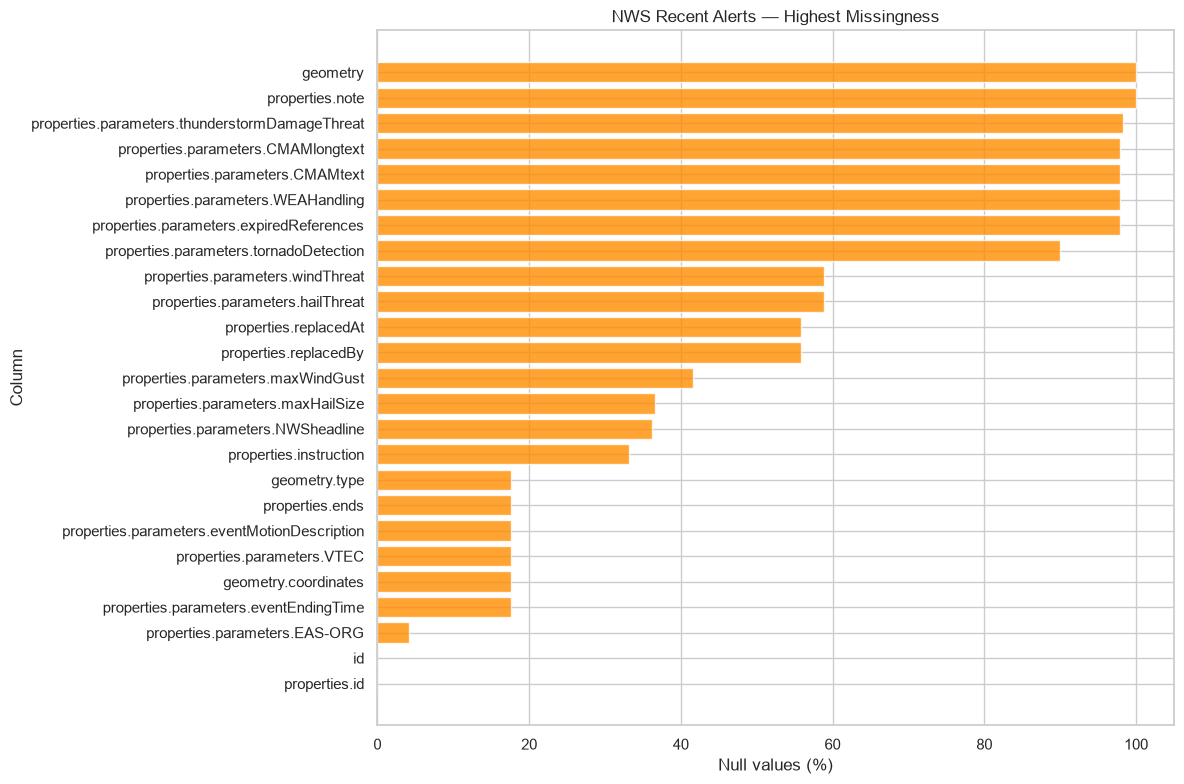

In [15]:
fig, ax = plt.subplots(figsize=(12, 8))
nws_null_plot = nws_profile.sort_values("null_pct", ascending=True).tail(25)
ax.barh(nws_null_plot["column"], nws_null_plot["null_pct"], color="darkorange", alpha=0.8)
ax.set(title="NWS Recent Alerts — Highest Missingness", xlabel="Null values (%)", ylabel="Column")
plt.tight_layout()
plt.show()

### 3.3 Alert distributions and update semantics

,event,count
0,Severe Thunderstorm Warning,136
1,Special Weather Statement,42
2,Tornado Watch,32
3,Tornado Warning,18
4,Dense Fog Advisory,6
5,Wind Advisory,4


,message_type,count
0,Alert,109
1,Update,84
2,Cancel,45


,severity,count
0,Severe,110
1,Moderate,51
2,Minor,45
3,Extreme,32


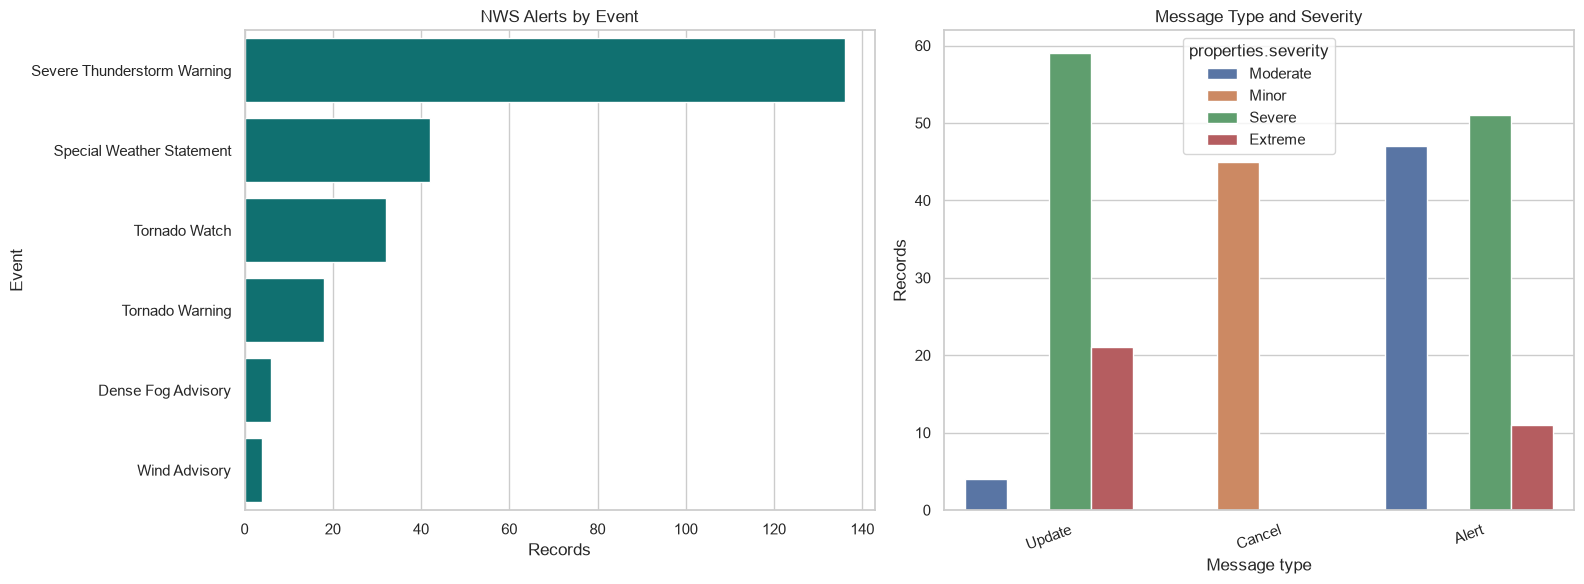

In [16]:
event_counts_nws = nws_raw["properties.event"].value_counts(dropna=False).rename_axis("event").reset_index(name="count")
message_counts = nws_raw["properties.messageType"].value_counts(dropna=False).rename_axis("message_type").reset_index(name="count")
severity_counts = nws_raw["properties.severity"].value_counts(dropna=False).rename_axis("severity").reset_index(name="count")

display(event_counts_nws)
display(message_counts)
display(severity_counts)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=event_counts_nws, x="count", y="event", ax=axes[0], color="teal")
axes[0].set(title="NWS Alerts by Event", xlabel="Records", ylabel="Event")
sns.countplot(data=nws_raw, x="properties.messageType", hue="properties.severity", ax=axes[1])
axes[1].set(title="Message Type and Severity", xlabel="Message type", ylabel="Records")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### 3.4 Temporal and geographic profile

In [17]:
nws = nws_raw.copy()
timestamp_columns = [
    "properties.sent",
    "properties.effective",
    "properties.onset",
    "properties.expires",
    "properties.ends",
]
for column in timestamp_columns:
    nws[column + "_parsed"] = pd.to_datetime(nws[column], errors="coerce", utc=True)

nws["affected_zone_count"] = nws["properties.affectedZones"].map(
    lambda value: len(value) if isinstance(value, list) else 0
)
nws["reference_count"] = nws["properties.references"].map(
    lambda value: len(value) if isinstance(value, list) else 0
)

temporal_rows = []
for column in timestamp_columns:
    parsed = nws[column + "_parsed"]
    temporal_rows.append({
        "field": column,
        "source_nulls": int(nws[column].isna().sum()),
        "parse_failures_non_null": int((parsed.isna() & nws[column].notna()).sum()),
        "minimum_utc": parsed.min(),
        "maximum_utc": parsed.max(),
    })
display(pd.DataFrame(temporal_rows))

geometry_types = pd.Series([
    "NULL" if feature.get("geometry") is None else feature["geometry"].get("type")
    for feature in recent_features
]).value_counts(dropna=False).rename_axis("geometry_type").reset_index(name="count")
display(geometry_types)
display(nws[["affected_zone_count", "reference_count"]].describe())

,field,source_nulls,parse_failures_non_null,minimum_utc,maximum_utc
0,properties.sent,0,0,2026-10-31 02:11:00+00:00,2026-11-03 09:56:00+00:00
1,properties.effective,0,0,2026-10-31 02:11:00+00:00,2026-11-03 09:56:00+00:00
2,properties.onset,0,0,2026-10-31 02:11:00+00:00,2026-11-03 09:56:00+00:00
3,properties.expires,0,0,2026-10-31 02:45:00+00:00,2026-11-03 11:00:00+00:00
4,properties.ends,42,0,2026-11-01 16:00:00+00:00,2026-11-03 10:00:00+00:00


,geometry_type,count
0,Polygon,196
1,NULL,42


,affected_zone_count,reference_count
count,238.000000,238.000000
mean,4.521008,0.941176
std,5.819143,1.142166
min,1.000000,0.000000
25%,2.000000,0.000000
50%,3.000000,1.000000
75%,5.000000,1.000000
max,47.000000,5.000000


### 3.5 Incremental poll comparison

An absent alert in a later active response is not automatically a source deletion. It may have expired or otherwise become inactive. Both raw responses remain the source of truth.

In [18]:
poll_1_features = nws_poll_1.get("features", [])
poll_2_features = nws_poll_2.get("features", [])
poll_1_by_id = {feature.get("id"): feature for feature in poll_1_features}
poll_2_by_id = {feature.get("id"): feature for feature in poll_2_features}

poll_1_ids = set(poll_1_by_id)
poll_2_ids = set(poll_2_by_id)
shared_ids = poll_1_ids & poll_2_ids
changed_ids = {
    alert_id
    for alert_id in shared_ids
    if stable_value(poll_1_by_id[alert_id]) != stable_value(poll_2_by_id[alert_id])
}

poll_comparison = pd.DataFrame([{
    "interval_seconds": (
        pd.Timestamp(nws_poll_2_metadata["retrieved_at_utc"])
        - pd.Timestamp(nws_poll_1_metadata["retrieved_at_utc"])
    ).total_seconds(),
    "poll_1_features": len(poll_1_features),
    "poll_2_features": len(poll_2_features),
    "new_in_poll_2": len(poll_2_ids - poll_1_ids),
    "no_longer_active": len(poll_1_ids - poll_2_ids),
    "shared_changed": len(changed_ids),
    "shared_unchanged": len(shared_ids - changed_ids),
    "collection_updated_changed": nws_poll_1.get("updated") != nws_poll_2.get("updated"),
    "document_hash_changed": sha256_file(NWS_POLL_1_PATH) != sha256_file(NWS_POLL_2_PATH),
}])
display(poll_comparison)

,interval_seconds,poll_1_features,poll_2_features,new_in_poll_2,no_longer_active,shared_changed,shared_unchanged,collection_updated_changed,document_hash_changed
0,5695.213749,0,0,0,0,0,0,True,True


## 4. GHCN-Daily / NCEI

In [19]:
ghcn_raw = pd.read_csv(GHCN_SAMPLE_PATH, parse_dates=["DATE"])
station_observation_payload = load_geojson(STATION_OBSERVATIONS_PATH)
station_features = station_observation_payload["features"]
station_observations = pd.json_normalize([feature["properties"] for feature in station_features])
print(f"GHCN-Daily rows: {len(ghcn_raw):,}; NWS station-observation features: {len(station_features):,}")

GHCN-Daily rows: 365; NWS station-observation features: 200


### 4.1 Basic GHCN DataFrame inspection

This section applies the Pandas operations covered in class: inspect the first rows, dimensions, columns, data types, descriptive statistics, missing values, and a simple monthly aggregation. The raw DataFrame is not modified.

In [20]:
print("Python object type:", type(ghcn_raw).__name__)
print("Shape:", ghcn_raw.shape)
print("Columns:", ghcn_raw.columns.tolist())
display(ghcn_raw.head())

ghcn_raw.info()

ghcn_numeric_summary = ghcn_raw[["PRCP", "TMAX", "TMIN"]].describe().T
display(ghcn_numeric_summary)

ghcn_missing_values = ghcn_raw.isnull().sum().to_frame("missing_values")
display(ghcn_missing_values)

ghcn_monthly_summary = (
    ghcn_raw.assign(month=ghcn_raw["DATE"].dt.month)
    .groupby("month")[["PRCP", "TMAX", "TMIN"]]
    .agg(["count", "mean"])
    .round(2)
)
display(ghcn_monthly_summary)

Python object type: DataFrame
Shape: (365, 12)
Columns: ['STATION', 'NAME', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'DATE', 'PRCP', 'PRCP_ATTRIBUTES', 'TMAX', 'TMAX_ATTRIBUTES', 'TMIN', 'TMIN_ATTRIBUTES']


,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,PRCP_ATTRIBUTES,TMAX,TMAX_ATTRIBUTES,TMIN,TMIN_ATTRIBUTES
0,USW00013967,"OKLAHOMA CITY WILL ROGERS WORLD AIRPORT, OK US",35.38843,-97.60035,389.9,2025-01-01,0.0,",,W,2400",7.2,",,W",-3.2,",,W"
1,USW00013967,"OKLAHOMA CITY WILL ROGERS WORLD AIRPORT, OK US",35.38843,-97.60035,389.9,2025-01-02,0.0,",,W,2400",13.9,",,W",-2.7,",,W"
2,USW00013967,"OKLAHOMA CITY WILL ROGERS WORLD AIRPORT, OK US",35.38843,-97.60035,389.9,2025-01-03,0.0,",,W,2400",10.0,",,W",-1.0,",,W"
3,USW00013967,"OKLAHOMA CITY WILL ROGERS WORLD AIRPORT, OK US",35.38843,-97.60035,389.9,2025-01-04,0.0,",,W,2400",12.2,",,W",5.6,",,W"
4,USW00013967,"OKLAHOMA CITY WILL ROGERS WORLD AIRPORT, OK US",35.38843,-97.60035,389.9,2025-01-05,0.0,"T,,W,2400",13.3,",,W",-8.8,",,W"


<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   STATION          365 non-null    str           
 1   NAME             365 non-null    str           
 2   LATITUDE         365 non-null    float64       
 3   LONGITUDE        365 non-null    float64       
 4   ELEVATION        365 non-null    float64       
 5   DATE             365 non-null    datetime64[us]
 6   PRCP             365 non-null    float64       
 7   PRCP_ATTRIBUTES  365 non-null    str           
 8   TMAX             365 non-null    float64       
 9   TMAX_ATTRIBUTES  365 non-null    str           
 10  TMIN             365 non-null    float64       
 11  TMIN_ATTRIBUTES  365 non-null    str           
dtypes: datetime64[us](1), float64(6), str(5)
memory usage: 34.3 KB


,count,mean,std,min,25%,50%,75%,max
PRCP,365.0,2.773425,8.458332,0.0,0.0,0.0,0.0,59.7
TMAX,365.0,22.878356,9.842956,-10.5,16.1,25.6,30.6,38.3
TMIN,365.0,10.248767,9.826320,-17.1,2.2,12.8,18.3,24.4


,missing_values
STATION,0
NAME,0
LATITUDE,0
LONGITUDE,0
ELEVATION,0
DATE,0
PRCP,0
PRCP_ATTRIBUTES,0
TMAX,0
TMAX_ATTRIBUTES,0


PRCP         TMAX         TMIN       
      count   mean count   mean count   mean
month                                       
1        31   0.50    31   7.76    31  -4.42
2        28   0.25    28  10.74    28  -3.35
3        31   1.73    31  21.17    31   6.32
4        30  10.62    30  22.45    30  10.89
5        31   4.58    31  25.95    31  13.84
6        30   6.33    30  30.93    30  19.72
7        31   2.09    31  33.22    31  21.89
8        31   3.82    31  31.78    31  20.94
9        30   0.51    30  29.98    30  17.04
10       31   1.66    31  25.95    31  12.75
11       30   1.10    30  19.48    30   6.03
12       31   0.07    31  14.33    31   0.43

In [21]:
ghcn_profile = pd.DataFrame([
    {"check": "rows", "result": len(ghcn_raw)},
    {"check": "columns", "result": len(ghcn_raw.columns)},
    {"check": "date_start", "result": ghcn_raw["DATE"].min().date().isoformat()},
    {"check": "date_end", "result": ghcn_raw["DATE"].max().date().isoformat()},
    {"check": "unique_dates", "result": ghcn_raw["DATE"].nunique()},
    {"check": "duplicate station-date keys", "result": ghcn_raw.duplicated(["STATION", "DATE"]).sum()},
    {"check": "stations", "result": ghcn_raw["STATION"].nunique()},
    {"check": "missing coordinate rows", "result": ghcn_raw[["LATITUDE", "LONGITUDE"]].isna().any(axis=1).sum()},
])
print(ghcn_profile.to_string(index=False))

                      check     result
                       rows        365
                    columns         12
                 date_start 2025-01-01
                   date_end 2025-12-31
               unique_dates        365
duplicate station-date keys          0
                   stations          1
    missing coordinate rows          0


In [22]:
ghcn_measurements = []
for field in ["PRCP", "TMAX", "TMIN"]:
    values = pd.to_numeric(ghcn_raw[field], errors="coerce")
    attrs = ghcn_raw[f"{field}_ATTRIBUTES"].fillna("").astype(str).str.split(",", expand=True)
    ghcn_measurements.append({
        "field": field,
        "rows": len(ghcn_raw),
        "null_values": int(values.isna().sum()),
        "minimum": values.min(),
        "maximum": values.max(),
        "mean": round(values.mean(), 3),
        "measurement_flags": attrs[0].replace("", "(blank)").value_counts().to_dict(),
        "quality_flags": attrs[1].replace("", "(blank)").value_counts().to_dict(),
        "source_flags": attrs[2].replace("", "(blank)").value_counts().to_dict(),
    })
print(pd.DataFrame(ghcn_measurements).to_string(index=False))

field  rows  null_values  minimum  maximum   mean         measurement_flags    quality_flags         source_flags
 PRCP   365            0      0.0     59.7  2.773 {'(blank)': 324, 'T': 41} {'(blank)': 365} {'W': 238, '1': 127}
 TMAX   365            0    -10.5     38.3 22.878          {'(blank)': 365} {'(blank)': 365} {'W': 238, '1': 127}
 TMIN   365            0    -17.1     24.4 10.249          {'(blank)': 365} {'(blank)': 365} {'W': 238, '1': 127}


The NCEI request asked for metric output. These ranges describe this one-station, one-year subset only. Preserve the attribute columns: PRCP has trace flags (`T`) on records whose numeric value is `0.0`, so dropping flags would conflate trace precipitation with ordinary zero.

### 4.2 NWS station observations

The nested GeoJSON properties are flattened into a Pandas DataFrame before the source-specific checks. The following inspection uses only basic DataFrame operations and keeps the captured payload unchanged.

In [23]:
station_basic_columns = [
    "timestamp", "stationId", "textDescription",
    "temperature.value", "relativeHumidity.value",
    "windSpeed.value", "windGust.value", "visibility.value",
]
station_basic_columns = [column for column in station_basic_columns if column in station_observations.columns]
station_basic_df = station_observations[station_basic_columns].copy()
station_basic_df["timestamp"] = pd.to_datetime(station_basic_df["timestamp"], utc=True, errors="coerce")

print("Python object type:", type(station_observations).__name__)
print("Shape:", station_observations.shape)
print("Flattened columns:", station_observations.columns.tolist())
display(station_basic_df.head())

station_basic_df.info()

display(station_basic_df.describe(include="number").T)
display(station_basic_df.isnull().sum().to_frame("missing_values"))

station_condition_counts = (
    station_basic_df["textDescription"]
    .value_counts(dropna=False)
    .rename_axis("text_description")
    .to_frame("observations")
)
display(station_condition_counts.head(10))

station_daily_counts = (
    station_basic_df.groupby(station_basic_df["timestamp"].dt.date)
    .size()
    .rename_axis("observation_date")
    .to_frame("observations")
)
display(station_daily_counts)

Python object type: DataFrame
Shape: (200, 59)
Flattened columns: ['@id', '@type', 'station', 'stationId', 'stationName', 'timestamp', 'rawMessage', 'textDescription', 'icon', 'presentWeather', 'cloudLayers', 'elevation.unitCode', 'elevation.value', 'temperature.unitCode', 'temperature.value', 'temperature.qualityControl', 'dewpoint.unitCode', 'dewpoint.value', 'dewpoint.qualityControl', 'windDirection.unitCode', 'windDirection.value', 'windDirection.qualityControl', 'windSpeed.unitCode', 'windSpeed.value', 'windSpeed.qualityControl', 'windGust.unitCode', 'windGust.value', 'windGust.qualityControl', 'barometricPressure.unitCode', 'barometricPressure.value', 'barometricPressure.qualityControl', 'seaLevelPressure.unitCode', 'seaLevelPressure.value', 'seaLevelPressure.qualityControl', 'visibility.unitCode', 'visibility.value', 'visibility.qualityControl', 'maxTemperatureLast24Hours.unitCode', 'maxTemperatureLast24Hours.value', 'minTemperatureLast24Hours.unitCode', 'minTemperatureLast24Hou

,timestamp,stationId,textDescription,temperature.value,relativeHumidity.value,windSpeed.value,windGust.value,visibility.value
0,2026-11-05 10:55:00+00:00,KOKC,Mostly Cloudy,11.0,None,11.124,NaN,16093.44
1,2026-11-05 10:52:00+00:00,KOKC,Mostly Cloudy,10.6,None,12.960,NaN,16090.00
2,2026-11-05 10:50:00+00:00,KOKC,Mostly Cloudy,11.0,None,12.960,NaN,16093.44
3,2026-11-05 10:45:00+00:00,KOKC,Partly Cloudy,11.0,None,11.124,NaN,16093.44
4,2026-11-05 10:40:00+00:00,KOKC,Mostly Clear,11.0,None,9.252,NaN,16093.44


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   timestamp               200 non-null    datetime64[us, UTC]
 1   stationId               200 non-null    str                
 2   textDescription         200 non-null    str                
 3   temperature.value       200 non-null    float64            
 4   relativeHumidity.value  0 non-null      object             
 5   windSpeed.value         199 non-null    float64            
 6   windGust.value          1 non-null      float64            
 7   visibility.value        200 non-null    float64            
dtypes: datetime64[us, UTC](1), float64(4), object(1), str(2)
memory usage: 12.6+ KB


,count,mean,std,min,25%,50%,75%,max
temperature.value,200.0,12.932500,3.858072,7.00,10.000,12.000,16.000,21.000
windSpeed.value,199.0,7.576643,5.530967,0.00,5.544,7.416,10.242,27.792
windGust.value,1.0,44.640000,NaN,44.64,44.640,44.640,44.640,44.640
visibility.value,200.0,16076.813400,160.480255,14484.10,16093.440,16093.440,16093.440,16093.440


,missing_values
timestamp,0
stationId,0
textDescription,0
temperature.value,0
relativeHumidity.value,200
windSpeed.value,1
windGust.value,199
visibility.value,0


,observations
text_description,
Clear,149
Mostly Clear,17
Cloudy,13
Mostly Cloudy,9
,9
Partly Cloudy,3


,observations
observation_date,
2026-11-03,9
2026-11-04,127
2026-11-05,64


In [24]:
station_timestamps = pd.to_datetime(station_observations["timestamp"], utc=True, errors="coerce")
station_coordinate_rows = [feature.get("geometry", {}).get("coordinates") for feature in station_features]
station_coordinate_pairs = [tuple(pair[:2]) for pair in station_coordinate_rows if isinstance(pair, list) and len(pair) >= 2]
station_observation_profile = pd.DataFrame([
    {"check": "station_features", "result": len(station_features)},
    {"check": "unique observation IDs", "result": pd.Series([feature.get("id") for feature in station_features]).nunique()},
    {"check": "unique station IDs", "result": station_observations["stationId"].nunique()},
    {"check": "missing/unparseable station_timestamps", "result": int(station_timestamps.isna().sum())},
    {"check": "timestamp start (UTC)", "result": station_timestamps.min().isoformat()},
    {"check": "timestamp end (UTC)", "result": station_timestamps.max().isoformat()},
    {"check": "duplicate observation station_timestamps", "result": int(station_timestamps.duplicated().sum())},
    {"check": "unique point coordinate pairs", "result": len(set(station_coordinate_pairs))},
    {"check": "response has pagination.next", "result": bool(station_observation_payload.get("pagination", {}).get("next"))},
])
print(station_observation_profile.to_string(index=False))

                                   check                    result
                        station_features                       200
                  unique observation IDs                       200
                      unique station IDs                         1
  missing/unparseable station_timestamps                         0
                   timestamp start (UTC) 2026-11-03T21:52:00+00:00
                     timestamp end (UTC) 2026-11-05T10:55:00+00:00
duplicate observation station_timestamps                         0
           unique point coordinate pairs                         1
            response has pagination.next                      True


In [25]:
station_measurement_fields = [
    "temperature", "dewpoint", "windDirection", "windSpeed", "windGust",
    "barometricPressure", "seaLevelPressure", "visibility",
    "maxTemperatureLast24Hours", "minTemperatureLast24Hours",
    "precipitationLastHour", "precipitationLast3Hours", "precipitationLast6Hours",
    "relativeHumidity", "heatIndex", "windChill",
]
station_field_rows = []
for field in station_measurement_fields:
    entries = [feature.get("properties", {}).get(field) for feature in station_features]
    values = [entry.get("value") if isinstance(entry, dict) else None for entry in entries]
    numeric = [value for value in values if isinstance(value, (int, float)) and not isinstance(value, bool)]
    units = sorted({entry.get("unitCode") for entry in entries if isinstance(entry, dict) and entry.get("unitCode")})
    qc = pd.Series([entry.get("qualityControl") for entry in entries if isinstance(entry, dict)]).value_counts(dropna=False).to_dict()
    station_field_rows.append({
        "field": field,
        "numeric_values": len(numeric),
        "null_or_missing_values": len(station_features) - len(numeric),
        "unit_codes": ", ".join(units),
        "quality_control_counts": qc,
        "minimum": min(numeric) if numeric else None,
        "maximum": max(numeric) if numeric else None,
    })
print(pd.DataFrame(station_field_rows).to_string(index=False))

                    field  numeric_values  null_or_missing_values             unit_codes quality_control_counts       minimum       maximum
              temperature             200                       0           wmoUnit:degC             {'V': 200}      7.000000     21.000000
                 dewpoint               0                     200           wmoUnit:degC             {'Z': 200}           NaN           NaN
            windDirection             199                       1 wmoUnit:degree_(angle)     {'V': 199, 'Z': 1}      0.000000    350.000000
                windSpeed             199                       1         wmoUnit:km_h-1     {'V': 199, 'Z': 1}      0.000000     27.792000
                 windGust               1                     199         wmoUnit:km_h-1     {'Z': 199, 'C': 1}     44.640000     44.640000
       barometricPressure             200                       0             wmoUnit:Pa             {'V': 200} 101219.160000 101659.390000
         seaLevelPre

In [26]:
station_poll2_payload = load_geojson(STATION_OBSERVATIONS_POLL2_PATH)
station_poll2_features = station_poll2_payload["features"]
station_poll1_by_id = {feature.get("id"): feature for feature in station_features}
station_poll2_by_id = {feature.get("id"): feature for feature in station_poll2_features}
poll1_observation_ids = set(station_poll1_by_id)
poll2_observation_ids = set(station_poll2_by_id)
shared_observation_ids = poll1_observation_ids & poll2_observation_ids
changed_observation_ids = {
    observation_id for observation_id in shared_observation_ids
    if stable_value(station_poll1_by_id[observation_id]) != stable_value(station_poll2_by_id[observation_id])
}
station_poll_interval_seconds = (
    pd.Timestamp(station_observations_poll2_metadata["retrieved_at_utc"])
    - pd.Timestamp(station_observations_metadata["nws_station_observations"]["local_capture_time_utc"])
).total_seconds()
station_poll_comparison = pd.DataFrame([{
    "interval_seconds": station_poll_interval_seconds,
    "poll_1_features": len(station_features),
    "poll_2_features": len(station_poll2_features),
    "shared_ids": len(shared_observation_ids),
    "new_in_poll_2": len(poll2_observation_ids - poll1_observation_ids),
    "not_in_poll_2_page": len(poll1_observation_ids - poll2_observation_ids),
    "changed_shared_payloads": len(changed_observation_ids),
    "unchanged_shared_payloads": len(shared_observation_ids - changed_observation_ids),
    "poll_2_next_page_present": bool(station_poll2_payload.get("pagination", {}).get("next")),
}])
display(station_poll_comparison)
for observation_id in changed_observation_ids:
    before = station_poll1_by_id[observation_id]["properties"]
    after = station_poll2_by_id[observation_id]["properties"]
    changed_fields = [key for key in sorted(set(before) | set(after)) if before.get(key) != after.get(key)]
    print("Changed observation:", observation_id)
    print("Changed properties:", changed_fields)


,interval_seconds,poll_1_features,poll_2_features,shared_ids,new_in_poll_2,not_in_poll_2_page,changed_shared_payloads,unchanged_shared_payloads,poll_2_next_page_present
0,3627.404123,200,200,197,3,3,0,197,True


### Common-region source-profile limits

- The GHCN profile is one station and 2025 only; it does not establish regional coverage or historical volume.
- Both KOKC samples are bounded first pages of 200 observations and include `pagination.next`. Their comparison demonstrates only the behavior observed in these two captures; it does not establish broader retention or the endpoint-wide revision policy.
- Null measurements are reported as observed availability, not automatically classified as defects; some elements may be conditional and QC codes need interpretation.
- Oklahoma/counties is the accepted common scope. One Oklahoma City station does not establish statewide representativeness; ADR 0004 defines the later multi-station coverage rule.
- Records entering or leaving the bounded 200-feature page are rolling-page observations, not evidence of deletion. Any shared-payload changes are reported by the executed comparison cell.

## 5. Evidence-backed quality observations and candidate pairs

The following tables are generated from captured samples. Quality observations must distinguish expected source semantics from actual defects. Cross-source rows are investigation candidates based on Oklahoma County text and interval overlap; they are not confirmed same-event matches.

In [27]:
quality_observations = pd.DataFrame([
    {
        "source": "NOAA Storm Events",
        "observation": "Missing begin coordinates",
        "affected_records": int((noaa["BEGIN_LAT_NUM"].isna() | noaa["BEGIN_LON_NUM"].isna()).sum()),
        "interpretation_status": "Requires CZ_TYPE and zone/county analysis",
    },
    {
        "source": "NOAA Storm Events",
        "observation": "Timestamp parse failures",
        "affected_records": int(noaa["BEGIN_PARSED_LOCAL"].isna().sum() + noaa["END_PARSED_LOCAL"].isna().sum()),
        "interpretation_status": "Verify examples before classifying",
    },
    {
        "source": "NWS Alerts",
        "observation": "Null geometry",
        "affected_records": int(sum(feature.get("geometry") is None for feature in recent_features)),
        "interpretation_status": "Check affectedZones and geocode first",
    },
    {
        "source": "NWS Alerts",
        "observation": "Null ends timestamp",
        "affected_records": int(nws["properties.ends"].isna().sum()),
        "interpretation_status": "May be valid CAP semantics",
    },
    {
        "source": "NWS Alerts",
        "observation": "Null instruction",
        "affected_records": int(nws["properties.instruction"].isna().sum()),
        "interpretation_status": "Assess by event and message type",
    },
])
station_quality_candidates = []
for field in ["barometricPressure", "maxTemperatureLast24Hours", "minTemperatureLast24Hours", "precipitationLast3Hours", "precipitationLastHour", "windGust"]:
    field_summary = next(row for row in station_field_rows if row["field"] == field)
    station_quality_candidates.append({"source":"NWS Station Observations", "observation":f"Null {field}.value in captured page", "affected_records":field_summary["null_or_missing_values"], "interpretation_status":"Sample-level missingness; assess optionality and QC before calling a defect"})
station_quality_candidates.extend([
    {"source": "GHCN-Daily", "observation": "PRCP trace flag with numeric zero", "affected_records": int(((ghcn_raw["PRCP"] == 0) & ghcn_raw["PRCP_ATTRIBUTES"].fillna("").str.startswith("T")).sum()), "interpretation_status": "Preserve trace flag; not equivalent to ordinary zero"},
    {"source": "NWS Station Observations", "observation": "Observation intervals vary", "affected_records": int((pd.Series(station_timestamps.sort_values().diff().dropna().dt.total_seconds()) != 300).sum()), "interpretation_status": "Intervals outside five minutes are observed cadence variation, not automatically a defect"},
])
if len(set(station_coordinate_pairs)) > 1:
    station_quality_candidates.append({"source": "NWS Station Observations", "observation": "Observation point varies within one station page", "affected_records": len(set(station_coordinate_pairs)), "interpretation_status": "Multiple coordinate pairs observed; inspect provider/station metadata before treating station location as fixed"})
quality_observations = pd.concat([quality_observations, pd.DataFrame(station_quality_candidates)], ignore_index=True)
display(quality_observations)

candidate_pairs = pd.read_csv(CANDIDATE_PAIRS_PATH)
assert len(candidate_pairs) == 5, "Workshop 1 requires five candidate pairs."
assert candidate_pairs["match_status"].eq("candidate_not_confirmed").all()
display(candidate_pairs[["candidate_pair_id", "alert_event", "alert_message_type", "alert_severity", "alert_effective", "observation_timestamp", "seconds_after_alert_effective", "text_description", "wind_speed_value", "wind_gust_value", "visibility_value", "match_status"]])

,source,observation,affected_records,interpretation_status
0,NOAA Storm Events,Missing begin coordinates,187,Requires CZ_TYPE and zone/county analysis
1,NOAA Storm Events,Timestamp parse failures,0,Verify examples before classifying
2,NWS Alerts,Null geometry,42,Check affectedZones and geocode first
3,NWS Alerts,Null ends timestamp,42,May be valid CAP semantics
4,NWS Alerts,Null instruction,79,Assess by event and message type
5,NWS Station Observations,Null barometricPressure.value in captured page,0,Sample-level missingness; assess optionality and QC before calling a defect
6,NWS Station Observations,Null maxTemperatureLast24Hours.value in captured page,200,Sample-level missingness; assess optionality and QC before calling a defect
7,NWS Station Observations,Null minTemperatureLast24Hours.value in captured page,200,Sample-level missingness; assess optionality and QC before calling a defect
8,NWS Station Observations,Null precipitationLast3Hours.value in captured page,200,Sample-level missingness; assess optionality and QC before calling a defect
9,NWS Station Observations,Null precipitationLastHour.value in captured page,200,Sample-level missingness; assess optionality and QC before calling a defect


,candidate_pair_id,alert_event,alert_message_type,alert_severity,alert_effective,observation_timestamp,seconds_after_alert_effective,text_description,wind_speed_value,wind_gust_value,visibility_value,match_status
0,PAIR-01,Dense Fog Advisory,Alert,Moderate,2026-11-01T06:34:00-06:00,2026-11-01T12:35:00+00:00,60,Fog,0.000,NaN,804.67,candidate_not_confirmed
1,PAIR-02,Special Weather Statement,Alert,Moderate,2026-11-02T12:48:00-06:00,2026-11-02T18:52:00+00:00,240,Light Drizzle,25.920,44.64,16090.00,candidate_not_confirmed
2,PAIR-03,Severe Thunderstorm Warning,Alert,Severe,2026-11-02T12:54:00-06:00,2026-11-02T19:05:00+00:00,660,Thunderstorms and Rain and Fog/Mist,29.520,46.44,2010.00,candidate_not_confirmed
3,PAIR-04,Severe Thunderstorm Warning,Update,Severe,2026-11-02T12:59:00-06:00,2026-11-02T19:10:00+00:00,660,Rain and Fog,16.668,NaN,804.67,candidate_not_confirmed
4,PAIR-05,Severe Thunderstorm Warning,Update,Severe,2026-11-02T13:04:00-06:00,2026-11-02T19:12:00+00:00,480,Thunderstorms and Rain and Fog/Mist,18.360,46.44,1210.00,candidate_not_confirmed


## 6. Preliminary source-to-canonical mapping

This is a profiling aid, not the final accepted data contract. The GHCN-Daily and station-observation mappings below preserve daily measurements and source-specific units/QC without treating every station reading as a discrete hazard event.

In [28]:
preliminary_mapping = pd.DataFrame([
    ["source_record_id", "NOAA", "EVENT_ID", "Verify uniqueness across selected years"],
    ["source_record_id", "NWS Alerts", "id / properties.id", "Compare values and update chains"],
    ["event_type", "NOAA", "EVENT_TYPE", "Controlled Storm Data event type"],
    ["event_type", "NWS Alerts", "properties.event", "Alert product name"],
    ["event_time", "NOAA", "BEGIN_DATE_TIME + CZ_TIMEZONE", "UTC conversion rule pending"],
    ["event_time", "NWS Alerts", "properties.effective", "RFC 3339 timestamp"],
    ["end_time", "NOAA", "END_DATE_TIME + CZ_TIMEZONE", "UTC conversion rule pending"],
    ["end_time", "NWS Alerts", "properties.ends / expires", "Semantic priority pending"],
    ["geometry", "NOAA", "BEGIN/END_LAT/LON + CZ identifiers", "Point may be absent for zone events"],
    ["geometry", "NWS Alerts", "geometry + affectedZones + geocode", "Null polygon can still have zones"],
    ["severity", "NOAA", "hazard-specific magnitude and impacts", "No universal source scale"],
    ["severity", "NWS Alerts", "properties.severity", "CAP categorical severity"],
    ["raw_reference", "NOAA", "archive filename + EVENT_ID", "Include archive checksum"],
    ["raw_reference", "NWS Alerts", "response path + feature id", "Include response checksum"],
    ["station_id", "GHCN-Daily", "STATION", "Preserve the original station identifier"],
    ["observation_date", "GHCN-Daily", "DATE", "Daily date; do not invent an observation time"],
    ["measurement_type/value", "GHCN-Daily", "PRCP/TMAX/TMIN + attributes", "Keep element, units, and M/Q/S flags together; not a discrete event by default"],
    ["station_id", "NWS Station Observations", "properties.stationId", "Preserve station identifier; test crosswalk to GHCN separately"],
    ["source_record_id", "NWS Station Observations", "feature.id / properties.@id", "ID includes timestamp; overlapping poll showed same-ID payload revision, so compare content hash as well"],
    ["event_time", "NWS Station Observations", "properties.timestamp", "Parse offset-aware timestamp to UTC; retain retrieval time separately"],
    ["measurement value/unit/QC", "NWS Station Observations", "properties.<element>.value/unitCode/qualityControl", "Preserve raw property, value, unit and QC; poll comparison demonstrated QC/value revision"],
    ["geometry", "NWS Station Observations", "feature.geometry.coordinates", "GeoJSON point; compare station coordinate variation before region mapping"],
    ["raw_reference", "GHCN-Daily and NWS Station Observations", "sample path + checksum", "Preserve raw response and its evidence metadata"],
], columns=["canonical_field", "source", "source_field", "note"])
display(preliminary_mapping)

,canonical_field,source,source_field,note
0,source_record_id,NOAA,EVENT_ID,Verify uniqueness across selected years
1,source_record_id,NWS Alerts,id / properties.id,Compare values and update chains
2,event_type,NOAA,EVENT_TYPE,Controlled Storm Data event type
3,event_type,NWS Alerts,properties.event,Alert product name
4,event_time,NOAA,BEGIN_DATE_TIME + CZ_TIMEZONE,UTC conversion rule pending
5,event_time,NWS Alerts,properties.effective,RFC 3339 timestamp
6,end_time,NOAA,END_DATE_TIME + CZ_TIMEZONE,UTC conversion rule pending
7,end_time,NWS Alerts,properties.ends / expires,Semantic priority pending
8,geometry,NOAA,BEGIN/END_LAT/LON + CZ identifiers,Point may be absent for zone events
9,geometry,NWS Alerts,geometry + affectedZones + geocode,Null polygon can still have zones


## 7. Limitations and next steps

### Current limitations

- Oklahoma/counties is accepted; one Oklahoma City station does not validate statewide coverage.
- The accepted baseline is 2010–2025 complete years, but this Workshop 1 sample covers one year and does not prove every station/year is complete.
- Both NWS Alerts active polls were empty; KOKC station polls had no changed shared payload, while retained KDEN evidence has one revision. Neither result establishes a service-wide policy.
- The recent NWS collection supports field profiling but is not a long-term archive.
- Null source values are observations, not automatically defects.
- No cleaning, imputation, outlier removal, or canonical normalization is performed here.

### Required next steps

1. Apply ADR 0004's multi-station completeness rule during historical ingestion.
2. Keep the five alert/observation pairs unconfirmed unless stronger spatial/event evidence is added.
3. Re-run the notebook after report/config edits and complete mutual review of the canonical mapping, source contracts, ER diagram, and architecture.
4. Validate the accepted preliminary Compound Hazard Index parameters in Workshop 4.
5. Export and visually inspect the final report PDF after the report review.

## 8. Execution summary

Run all cells from top to bottom before submission. Save outputs only after every assertion passes and the results have been reviewed against the registered evidence.

In [29]:
execution_summary = pd.DataFrame([
    {"source": "NOAA Storm Events", "records": len(noaa_raw), "section_implemented": True},
    {"source": "NWS Alerts active poll 1", "records": len(poll_1_features), "section_implemented": True},
    {"source": "NWS Alerts active poll 2", "records": len(poll_2_features), "section_implemented": True},
    {"source": "NWS Alerts recent window", "records": len(recent_features), "section_implemented": True},
    {"source": "GHCN-Daily", "records": len(ghcn_raw), "section_implemented": True},
    {"source": "NWS Station Observations poll 1", "records": len(station_features), "section_implemented": True},
    {"source": "NWS Station Observations poll 2", "records": len(station_poll2_features), "section_implemented": True},
])
display(execution_summary)

print("Profiles and preserved samples are present for all four sources; Oklahoma/counties and the temporal scope are accepted.")
print("This successful top-to-bottom execution still requires teammate review before submission.")

,source,records,section_implemented
0,NOAA Storm Events,250,True
1,NWS Alerts active poll 1,0,True
2,NWS Alerts active poll 2,0,True
3,NWS Alerts recent window,238,True
4,GHCN-Daily,365,True
5,NWS Station Observations poll 1,200,True
6,NWS Station Observations poll 2,200,True


Profiles and preserved samples are present for all four sources; Oklahoma/counties and the temporal scope are accepted.
This successful top-to-bottom execution still requires teammate review before submission.
